In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_pickle("dane.pkl")
df["Type_num"] = df["Type"].map({"A": 0, "B": 1, "C": 2})
df["Month"] = df["Date"].dt.month
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)

print(df.shape)


(421570, 20)


In [3]:
import joblib
from pathlib import Path

MODELE = Path(r"C:\Users\Alicja\Desktop\kurs-datascience\Data Science\Prognoza_sprzedazy\modele")

model_baz_final = joblib.load(MODELE / "model_bazowy.joblib")
model_cal_final = joblib.load(MODELE / "model_calkowity.joblib")
print("modele wczytane")

modele wczytane


In [4]:
pary = df[["Store", "Dept", "Type_num", "Size"]].drop_duplicates(["Store", "Dept"])
tygodnie_2013 = pd.date_range("2013-01-04", "2013-12-27", freq="7D")

przyszlosc = pary.merge(pd.DataFrame({"Date": tygodnie_2013}), how="cross")
przyszlosc["Month"] = przyszlosc["Date"].dt.month
przyszlosc["WeekOfYear"] = przyszlosc["Date"].dt.isocalendar().week.astype(int)

print(przyszlosc.shape)
przyszlosc.head()

(173212, 7)


,Store,Dept,Type_num,Size,Date,Month,WeekOfYear
0,1,1,0,151315,2013-01-04,1,1
1,1,1,0,151315,2013-01-11,1,2
2,1,1,0,151315,2013-01-18,1,3
3,1,1,0,151315,2013-01-25,1,4
4,1,1,0,151315,2013-02-01,2,5


In [17]:
swieta_2013 = pd.to_datetime(["2013-02-08", "2013-09-06", "2013-11-29", "2013-12-27"])
przyszlosc["IsHoliday"] = przyszlosc["Date"].isin(swieta_2013).astype(float)

unikalne_swieta = przyszlosc[przyszlosc["IsHoliday"] == 1]["Date"].dt.strftime('%Y-%m-%d').unique()

print("Dni świąteczne (IsHoliday = 1) w 2013 roku:")

for data in unikalne_swieta:
    print(f"{data}")

Dni świąteczne (IsHoliday = 1) w 2013 roku:
2013-02-08
2013-09-06
2013-11-29
2013-12-27


In [23]:
markdown = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]
cechy_zewn = ["Temperature", "Fuel_Price", "CPI", "Unemployment"] + markdown

kolumny_do_usuniecia = [c for c in cechy_zewn if c in przyszlosc.columns]
if kolumny_do_usuniecia:
    przyszlosc = przyszlosc.drop(columns=kolumny_do_usuniecia)

typowe = df[df["Date"] > "2011-10-28"].groupby("Store")[cechy_zewn].mean().reset_index()

przyszlosc = przyszlosc.merge(typowe, on="Store", how="left")

print(f"Łączna liczba braków danych (NaN) w cechach zewnętrznych: {przyszlosc[cechy_zewn].isna().sum().sum()}")

if przyszlosc[cechy_zewn].isna().sum().sum() == 0:
    print("Sukces! Wszystkie cechy zewnętrzne zostały poprawnie uzupełnione.")
else:
    print("Uwaga! Wykryto braki danych, które wymagają uzupełnienia.")

Łączna liczba braków danych (NaN) w cechach zewnętrznych: 0
Sukces! Wszystkie cechy zewnętrzne zostały poprawnie uzupełnione.


In [ ]:
markdown = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]

bazowy = ["Store", "Dept", "Type_num", "Size", "Month", "WeekOfYear",
          "IsHoliday", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
calkowity = bazowy + markdown

Sprzedaż firmy: historia i prognoza na 2013 (mln)

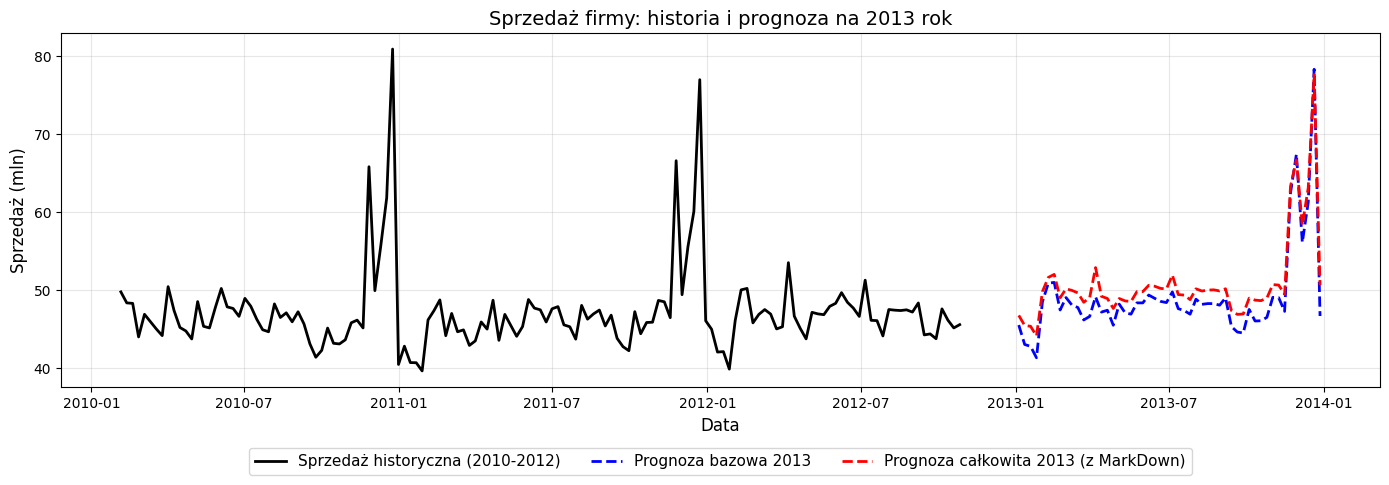

In [37]:
hist_firma = df.groupby("Date")["Weekly_Sales"].sum() / 1_000_000
prognoza = przyszlosc.groupby("Date")[["prognoza_bazowa", "prognoza_calkowita"]].sum() / 1_000_000

plt.figure(figsize=(14, 5))
plt.plot(hist_firma.index, hist_firma.values, label="Sprzedaż historyczna (2010-2012)", color="black", linewidth=2)
plt.plot(prognoza.index, prognoza["prognoza_bazowa"], label="Prognoza bazowa 2013", color="blue", linestyle="--", linewidth=2)
plt.plot(prognoza.index, prognoza["prognoza_calkowita"], label="Prognoza całkowita 2013 (z MarkDown)", color="red", linestyle="--", linewidth=2)
plt.title("Sprzedaż firmy: historia i prognoza na 2013 rok", fontsize=14)
plt.ylabel("Sprzedaż (mln)", fontsize=12)
plt.xlabel("Data", fontsize=12)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Podgląd tabeli z wynikami na rok 2013

In [25]:
wynik = przyszlosc[["Store", "Dept", "Date", "prognoza_bazowa", "prognoza_calkowita"]].copy()
wynik[["prognoza_bazowa", "prognoza_calkowita"]] = wynik[["prognoza_bazowa", "prognoza_calkowita"]].round(0)

wynik[(wynik["Store"] == 1) & (wynik["Dept"] == 1)].head(10)

,Store,Dept,Date,prognoza_bazowa,prognoza_calkowita
0,1,1,2013-01-04,16934.0,23187.0
1,1,1,2013-01-11,17221.0,23177.0
2,1,1,2013-01-18,17457.0,23497.0
3,1,1,2013-01-25,16501.0,23096.0
4,1,1,2013-02-01,24645.0,27459.0
5,1,1,2013-02-08,35790.0,35321.0
6,1,1,2013-02-15,44934.0,41988.0
7,1,1,2013-02-22,18794.0,24103.0
8,1,1,2013-03-01,18918.0,24825.0
9,1,1,2013-03-08,19828.0,25892.0


In [35]:
kolumny = ["Date"] + calkowity
wszystko = pd.concat([df[kolumny], przyszlosc[kolumny]], ignore_index=True)


def predict(store, dept, week): # zwraca prognozę sprzedaży bazowej i całkowitej dla sklepu, działu i tygodnia.
    data = pd.to_datetime(week, dayfirst=True)
    tydzien = data + pd.Timedelta(days=(4 - data.weekday()) % 7)
    wiersz = wszystko[(wszystko["Store"] == store)
                      & (wszystko["Dept"] == dept)
                      & (wszystko["Date"] == tydzien)]

    if wiersz.empty:
        return "Brak danych dla tego sklepu, działu i tygodnia."
    
    bazowa = max(model_baz_final.predict(wiersz[bazowy].astype(float))[0], 0)
    calkowita = max(model_cal_final.predict(wiersz[calkowity].astype(float))[0], 0)

    return {
        "tydzień kończący się": str(tydzien.date()),
        "sprzedaż bazowa": round(float(bazowa)),
        "sprzedaż całkowita": round(float(calkowita)),
    }


print("Wynik dla daty historycznej:\n", predict(1, 1, "9/4/2010"))
print("Wynik dla przyszłego okresu świątecznego:\n", predict(1, 1, "20/12/2013"))

Wynik dla daty historycznej:
 {'tydzień kończący się': '2010-04-09', 'sprzedaż bazowa': 38322, 'sprzedaż całkowita': 39223}
Wynik dla przyszłego okresu świątecznego:
 {'tydzień kończący się': '2013-12-20', 'sprzedaż bazowa': 60271, 'sprzedaż całkowita': 50258}


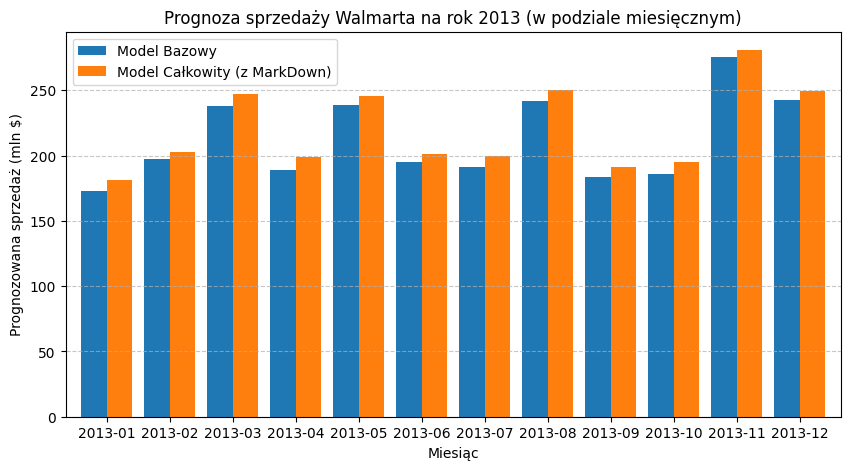

In [30]:
import matplotlib.pyplot as plt

miesieczna_2013 = (
    przyszlosc.groupby(przyszlosc["Date"].dt.to_period("M"))
    [["prognoza_bazowa", "prognoza_calkowita"]]
    .sum() / 1_000_000
)

miesieczna_2013.plot(kind="bar", figsize=(10, 5), width=0.8)
plt.title("Prognoza sprzedaży Walmarta na rok 2013 (w podziale miesięcznym)")
plt.ylabel("Prognozowana sprzedaż (mln $)")
plt.xlabel("Miesiąc")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(["Model Bazowy", "Model Całkowity (z MarkDown)"])
plt.show()

In [33]:
# Tworzę tabelę z przyporządkowaniem sklepu do jego literowego typu (A, B, C)
typy_sklepow = df[["Store", "Type"]].drop_duplicates().set_index("Store")

top_sklepy = (
    przyszlosc.groupby("Store")["prognoza_calkowita"]
    .sum() 
    / 1_000_000
)

top_sklepy_df = pd.DataFrame({"Sprzedaż_mln": top_sklepy})
top_sklepy_df = top_sklepy_df.join(typy_sklepow)
top_sklepy_df = top_sklepy_df.sort_values(by="Sprzedaż_mln", ascending=False).head(10)

print(f"10 sklepów z najwyższą prognozowaną sprzedażą w 2013 roku:\n{'Sklep (Store)':<15} | {'Typ sklepu':<12} | {'Prognoza (mln $)':<15}")

for store, row in top_sklepy_df.iterrows():
    typ = row['Type'] if 'Type' in row and not pd.isna(row['Type']) else "N/D"
    sprzedaz = row['Sprzedaż_mln']
    print(f"Sklep {int(store):<8} | Typ: {typ:<8} | {sprzedaz:8.2f} mln $")

10 sklepów z najwyższą prognozowaną sprzedażą w 2013 roku:
Sklep (Store)   | Typ sklepu   | Prognoza (mln $)
Sklep 4        | Typ: A        |   122.36 mln $
Sklep 20       | Typ: A        |   117.68 mln $
Sklep 13       | Typ: A        |   114.60 mln $
Sklep 14       | Typ: A        |   108.26 mln $
Sklep 2        | Typ: A        |   105.97 mln $
Sklep 10       | Typ: B        |   105.13 mln $
Sklep 27       | Typ: A        |    94.64 mln $
Sklep 1        | Typ: A        |    88.07 mln $
Sklep 6        | Typ: A        |    86.56 mln $
Sklep 39       | Typ: A        |    82.09 mln $
